In [1]:

import os

dataset_path = "/kaggle/input/datasets/uday9081/delhi-traffic-dataset"

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        print(os.path.join(root, file))


/kaggle/input/datasets/uday9081/delhi-traffic-dataset/delhi_traffic_features.csv


In [3]:

import pandas as pd

file_path = "/kaggle/input/datasets/uday9081/delhi-traffic-dataset/delhi_traffic_features.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (4000, 10)


,Trip_ID,start_area,end_area,distance_km,time_of_day,day_of_week,weather_condition,traffic_density_level,road_type,average_speed_kmph
0,TRIP_00001,Vasant Kunj,Kalkaji,9.44,Night,Weekday,Clear,Low,Main Road,37.8
1,TRIP_00002,Greater Kailash,Kalkaji,2.15,Night,Weekend,Clear,Low,Main Road,42.7
2,TRIP_00003,Janakpuri,Model Town,14.54,Morning Peak,Weekday,Rain,High,Inner Road,9.7
3,TRIP_00004,Punjabi Bagh,Dwarka,11.86,Night,Weekday,Clear,Low,Highway,68.5
4,TRIP_00005,Rohini,Chandni Chowk,20.26,Afternoon,Weekday,Fog,Medium,Highway,30.3


In [4]:

import pandas as pd

# Check the original dataset
print("Original shape:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Display missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display column names and data types
print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())


Original shape: (4000, 10)

Missing values:
Trip_ID                  0
start_area               0
end_area                 0
distance_km              0
time_of_day              0
day_of_week              0
weather_condition        0
traffic_density_level    0
road_type                0
average_speed_kmph       0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_ID                4000 non-null   object 
 1   start_area             4000 non-null   object 
 2   end_area               4000 non-null   object 
 3   distance_km            4000 non-null   float64
 4   time_of_day            4000 non-null   object 
 5   day_of_week            4000 non-null   object 
 6   weather_condition      4000 non-null   object 
 7   traffic_density_level  4000 non-null   object 
 8   road_type          

,Trip_ID,start_area,end_area,distance_km,time_of_day,day_of_week,weather_condition,traffic_density_level,road_type,average_speed_kmph
0,TRIP_00001,Vasant Kunj,Kalkaji,9.44,Night,Weekday,Clear,Low,Main Road,37.8
1,TRIP_00002,Greater Kailash,Kalkaji,2.15,Night,Weekend,Clear,Low,Main Road,42.7
2,TRIP_00003,Janakpuri,Model Town,14.54,Morning Peak,Weekday,Rain,High,Inner Road,9.7
3,TRIP_00004,Punjabi Bagh,Dwarka,11.86,Night,Weekday,Clear,Low,Highway,68.5
4,TRIP_00005,Rohini,Chandni Chowk,20.26,Afternoon,Weekday,Fog,Medium,Highway,30.3


In [5]:

print("Available columns:")
for col in df.columns:
    print(col)

print("\nNumeric columns:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(exclude="number").columns.tolist())


Available columns:
Trip_ID
start_area
end_area
distance_km
time_of_day
day_of_week
weather_condition
traffic_density_level
road_type
average_speed_kmph

Numeric columns:
['distance_km', 'average_speed_kmph']

Categorical columns:
['Trip_ID', 'start_area', 'end_area', 'time_of_day', 'day_of_week', 'weather_condition', 'traffic_density_level', 'road_type']


In [6]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check the target variable
print("\nAverage speed statistics:")
print(df["average_speed_kmph"].describe())

# Check traffic density categories
print("\nTraffic density distribution:")
print(df["traffic_density_level"].value_counts(dropna=False))


Missing values:
Trip_ID                  0
start_area               0
end_area                 0
distance_km              0
time_of_day              0
day_of_week              0
weather_condition        0
traffic_density_level    0
road_type                0
average_speed_kmph       0
dtype: int64

Duplicate rows: 0

Average speed statistics:
count    4000.000000
mean       28.085300
std        17.057224
min         4.800000
25%        14.500000
50%        24.200000
75%        38.200000
max        93.300000
Name: average_speed_kmph, dtype: float64

Traffic density distribution:
traffic_density_level
High         1348
Medium       1055
Very High     979
Low           618
Name: count, dtype: int64


In [7]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Remove rows where the target is missing
data = df.dropna(subset=["average_speed_kmph"]).copy()

# Remove Trip_ID because it is an identifier, not a useful traffic feature
X = data.drop(columns=["average_speed_kmph", "Trip_ID"])
y = data["average_speed_kmph"]

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include="number"
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ]
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)


Training rows: 3200
Testing rows: 800
Numerical features: ['distance_km']
Categorical features: ['start_area', 'end_area', 'time_of_day', 'day_of_week', 'weather_condition', 'traffic_density_level', 'road_type']


In [8]:

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

# Predict traffic speed
y_pred = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(mae, 3), "km/h")
print("RMSE:", round(rmse, 3), "km/h")
print("R² Score:", round(r2, 3))


Random Forest Results
---------------------
MAE: 3.577 km/h
RMSE: 4.906 km/h
R² Score: 0.919


In [9]:

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []
trained_models = {}

for name, regressor in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", regressor)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")

print("Model comparison:")
display(results_df.round(3))


Model comparison:


,Model,MAE,RMSE,R2 Score
3,Gradient Boosting,3.502,4.590,0.929
2,Random Forest,3.577,4.906,0.919
1,Decision Tree,4.596,6.480,0.859
0,Linear Regression,5.133,6.671,0.851


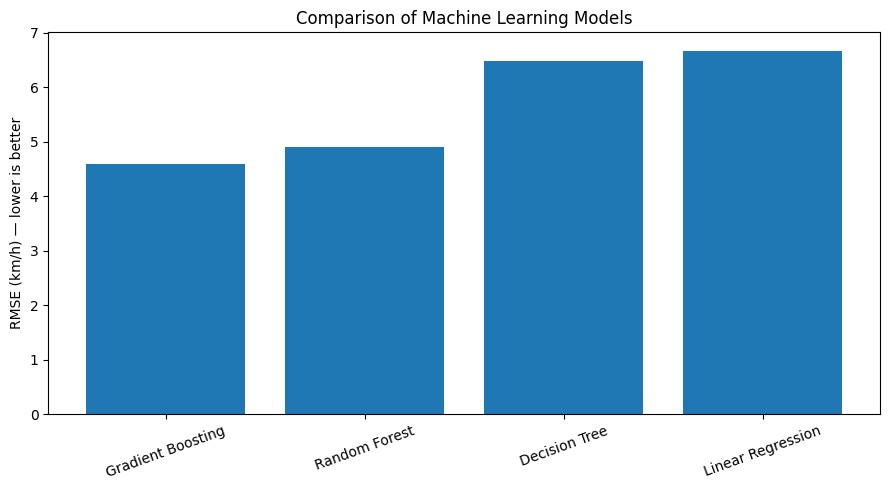

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Comparison of Machine Learning Models")
plt.ylabel("RMSE (km/h) — lower is better")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


Best model: Gradient Boosting


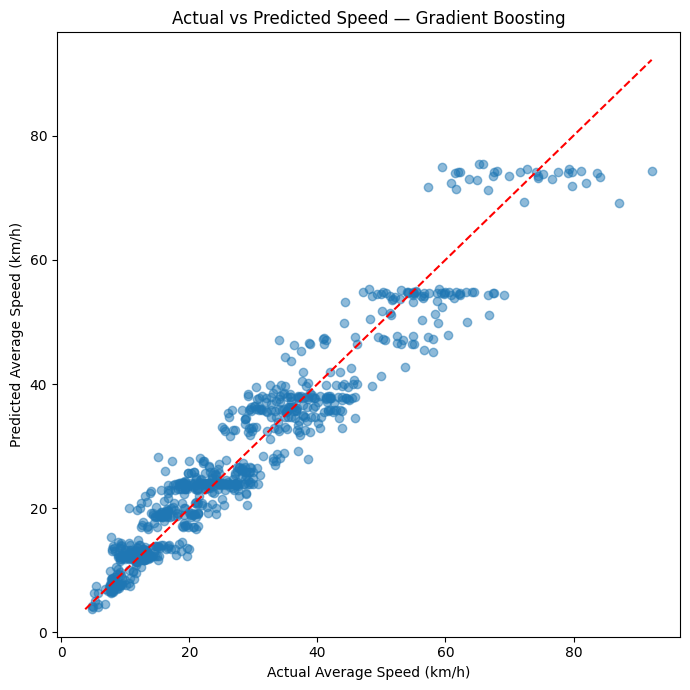

In [11]:

import matplotlib.pyplot as plt
import numpy as np

# Select model with lowest RMSE
best_model_name = results_df.sort_values("RMSE").iloc[0]["Model"]
best_model = trained_models[best_model_name]

# Predict test data
y_pred_best = best_model.predict(X_test)

print("Best model:", best_model_name)

# Plot actual vs predicted values
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_best, alpha=0.5)

lower = min(y_test.min(), y_pred_best.min())
upper = max(y_test.max(), y_pred_best.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual Average Speed (km/h)")
plt.ylabel("Predicted Average Speed (km/h)")
plt.title(f"Actual vs Predicted Speed — {best_model_name}")
plt.tight_layout()
plt.show()


In [12]:

import joblib
import os

os.makedirs("/kaggle/working/models", exist_ok=True)

model_path = "/kaggle/working/models/traffic_speed_model.pkl"

joblib.dump(best_model, model_path)

print("Model saved at:", model_path)


Model saved at: /kaggle/working/models/traffic_speed_model.pkl


In [13]:

import joblib

loaded_model = joblib.load(
    "/kaggle/working/models/traffic_speed_model.pkl"
)

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

print("Model loaded successfully!")
print("Predicted speed:", round(prediction, 2), "km/h")
print("Actual speed:", round(actual, 2), "km/h")
print("Absolute error:", round(abs(prediction - actual), 2), "km/h")


Model loaded successfully!
Predicted speed: 27.24 km/h
Actual speed: 28.4 km/h
Absolute error: 1.16 km/h


In [15]:

print("Traffic density categories:")
print(df["traffic_density_level"].value_counts(dropna=False))

print("\nAverage speed by traffic density:")

display(
    df.groupby("traffic_density_level", dropna=False)
      ["average_speed_kmph"]
      .agg(["count", "mean", "min", "max"])
)

print("\nMissing traffic labels:")
print(df["traffic_density_level"].isnull().sum())


Traffic density categories:
traffic_density_level
High         1348
Medium       1055
Very High     979
Low           618
Name: count, dtype: int64

Average speed by traffic density:


,count,mean,min,max
traffic_density_level,,,,
High,1348,24.208012,7.6,46.2
Low,618,46.949515,10.2,93.3
Medium,1055,36.535450,7.7,69.2
Very High,979,12.409704,4.8,23.6



Missing traffic labels:
0


Accuracy: 0.78

Classification report:
              precision    recall  f1-score   support

        High       0.81      0.84      0.82       269
         Low       0.68      0.54      0.60       124
      Medium       0.65      0.66      0.65       211
   Very High       0.94      0.98      0.96       196

    accuracy                           0.78       800
   macro avg       0.77      0.75      0.76       800
weighted avg       0.78      0.78      0.78       800



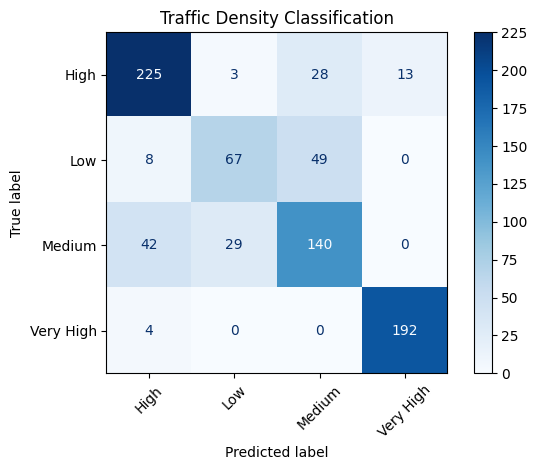


Classifier saved successfully!


In [16]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import joblib
import os

# Remove rows with missing target labels
data_cls = df.dropna(subset=["traffic_density_level"]).copy()

# Target: traffic density category
y_cls = data_cls["traffic_density_level"]

# Features: exclude IDs and target
X_cls = data_cls.drop(
    columns=["Trip_ID", "traffic_density_level"]
)

# Identify feature types
cat_cols = X_cls.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = X_cls.select_dtypes(
    include="number"
).columns.tolist()

# Preprocess features
preprocessor_cls = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

# Stratified split preserves category proportions
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls,
    test_size=0.2,
    random_state=42,
    stratify=y_cls
)

# Create and train classifier
congestion_model = Pipeline([
    ("preprocessor", preprocessor_cls),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

congestion_model.fit(X_train_cls, y_train_cls)

# Evaluate
y_pred_cls = congestion_model.predict(X_test_cls)

print("Accuracy:", round(accuracy_score(y_test_cls, y_pred_cls), 4))
print("\nClassification report:")
print(classification_report(y_test_cls, y_pred_cls, zero_division=0))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    y_pred_cls,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Traffic Density Classification")
plt.tight_layout()
plt.show()

# Save the trained classifier
os.makedirs("/kaggle/working/models", exist_ok=True)

joblib.dump(
    congestion_model,
    "/kaggle/working/models/congestion_classifier.pkl"
)

print("\nClassifier saved successfully!")


In [17]:

import joblib

classifier_path = "/kaggle/working/models/congestion_classifier.pkl"

loaded_classifier = joblib.load(classifier_path)

sample = X_test_cls.iloc[[0]]
predicted_density = loaded_classifier.predict(sample)[0]
actual_density = y_test_cls.iloc[0]

print("Classifier loaded successfully!")
print("Predicted traffic density:", predicted_density)
print("Actual traffic density:", actual_density)
print("Correct prediction:", predicted_density == actual_density)


Classifier loaded successfully!
Predicted traffic density: Low
Actual traffic density: Low
Correct prediction: True
